In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pyam
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredOffsetbox, AuxTransformBox
from matplotlib.transforms import Affine2D
from matplotlib import cm

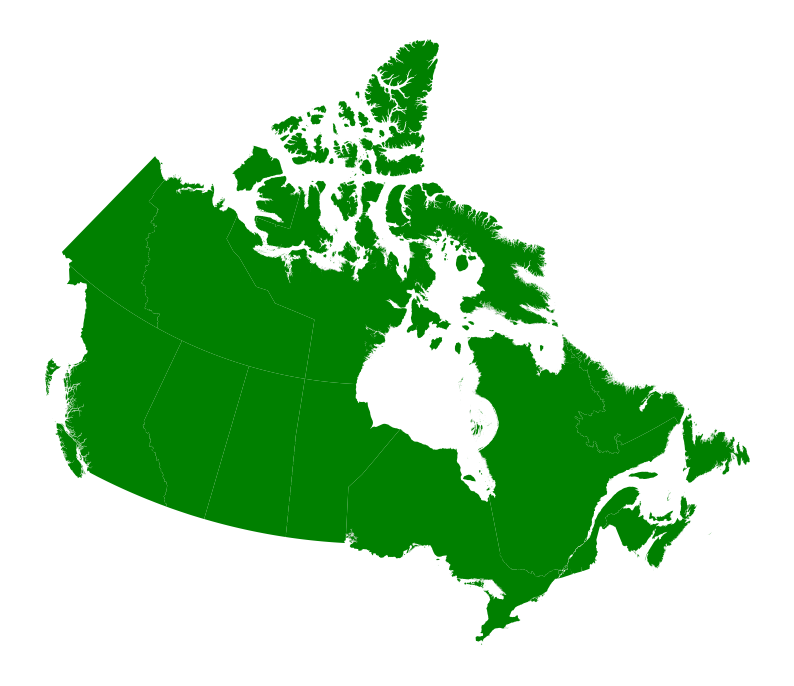

In [41]:
# Path to your shapefile (make sure all required files are in the same directory)
shapefile_path = '/Users/muhammadawais/Documents/GitHub/message-ix-canada/data/delineation/lpr_000b16a_e.shp'

# Load the shapefile using geopandas
gdf = gpd.read_file(shapefile_path)

# Create a plot with light green color filling the geometries
ax = gdf.plot(figsize=(10, 10), color='green', edgecolor='none')

# Remove axis labels and ticks
ax.set_axis_off()

# Show the plot
plt.show()

In [42]:
df = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_baseline_BD.xlsx')
df1 = pd.read_excel('/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output/MESSAGEix-CA_netzero.xlsx')

In [43]:
df_hydrogen = df[df['Variable'] == 'Final Energy|Hydrogen']

In [ ]:
df_hydrogen['Sum'] = df_hydrogen[2030]+ df_hydrogen[2040]+ df_hydrogen[2050]

In [44]:
df_plot = df_hydrogen[[2050,'Region']]

In [46]:
df_plot

,value,region
1381,79.589038,Alberta
1451,0.170041,BritishColumbia
1521,0.000000,Canada
1591,0.179702,Manitoba
1661,0.027567,NewBrunswick
1731,0.080220,NewfoundlandandLabrador
1801,0.000000,NorthwestTerritories
1871,0.124890,NovaScotia
1941,0.000000,Nunavut
2011,0.959305,Ontario


/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_73098/2872835915.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot.rename(columns={2050: 'value','Region':'region'}, inplace=True)
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_73098/2872835915.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['region'] = df_plot['region'].str.replace(' ', '')
/var/folders/kp/fywbc9rj4lld_vk6pm6m71g00000gn/T/ipykernel_73098/2872835915.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be re

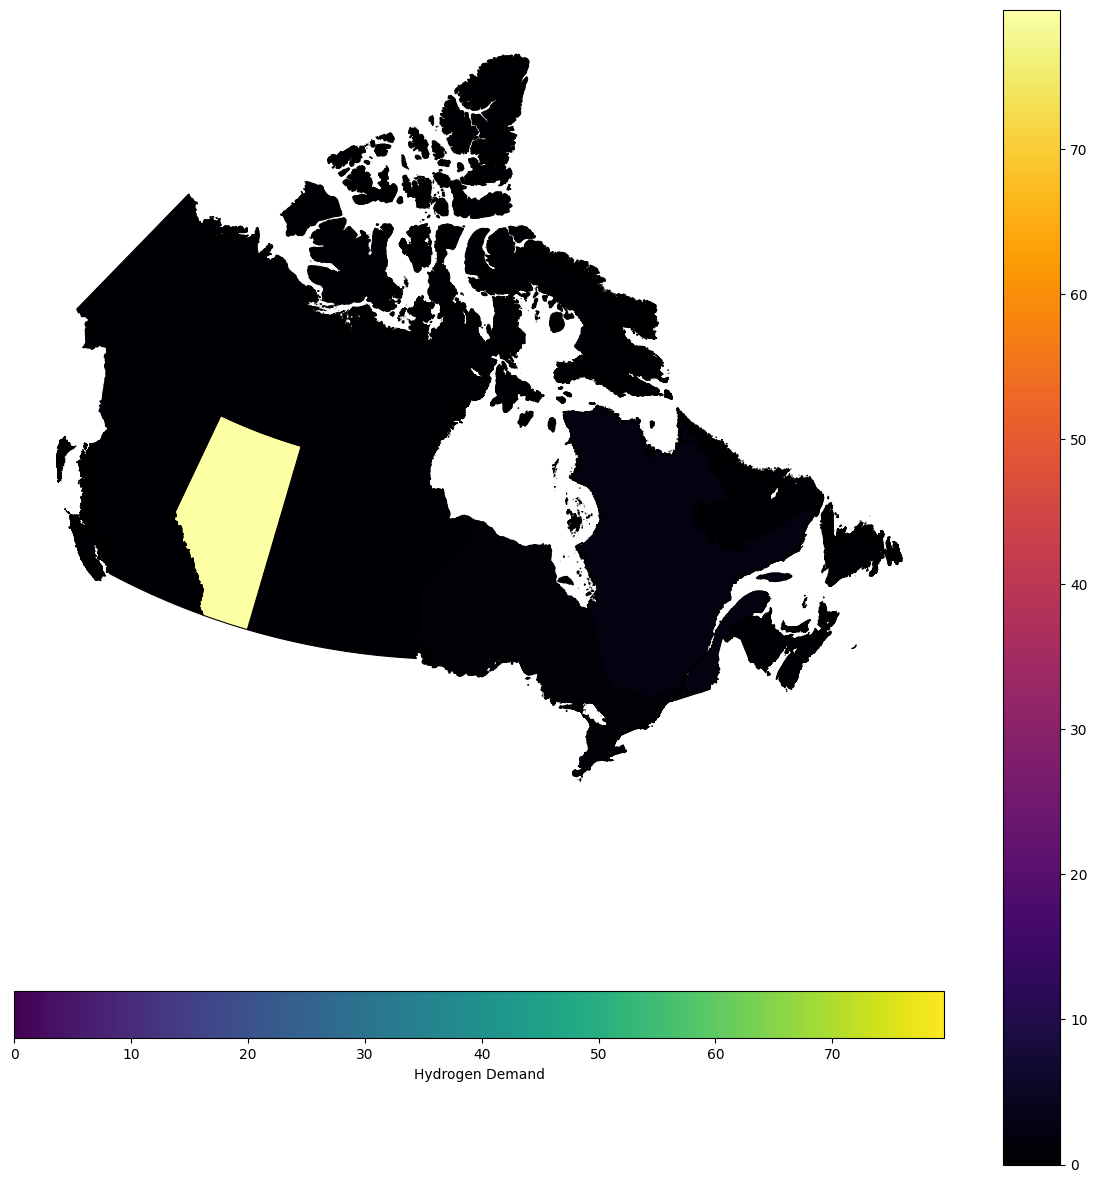

In [45]:


df_plot.rename(columns={2050: 'value','Region':'region'}, inplace=True)
gdf.rename(columns={'PRENAME':'region'}, inplace=True)
# Align the region names by removing spaces in the CSV file region column
df_plot['region'] = df_plot['region'].str.replace(' ', '')

# Align with the shapefile's province names (PRENAME)
gdf['region'] = gdf['region'].str.replace(' ', '')

# Merge the electricity generation data with the GeoDataFrame
gdf = gdf.merge(df_plot[['region', 'value']], on='region', how='left')

# Create a colormap for value differences
norm = plt.Normalize(vmin=gdf['value'].min(), vmax=gdf['value'].max())
cmap = cm.get_cmap('viridis')

# Plot the map with province polygons colored by electricity generation values for the chosen year
fig, ax = plt.subplots(1, 1, figsize=(15, 15))
gdf.plot(column='value', cmap='inferno', linewidth=0.8, ax=ax, edgecolor='black', legend=True)

# Add a colorbar for the scale
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # We don't need an actual array here
fig.colorbar(sm, ax=ax, orientation='horizontal', label=f'Hydrogen Demand')
ax.set_axis_off()
# Show the plot
plt.show()

In [128]:
# After plotting the map
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()

print(f"Longitude (X-axis) limits: {x_limits}")
print(f"Latitude (Y-axis) limits: {y_limits}")


Longitude (X-axis) limits: (3423124.13043, 9282051.51243)
Latitude (Y-axis) limits: (430196.84214275004, 5471321.2350022495)


[INFO] 15:11:17 - pyam.plotting: >=13 labels, not applying legend


<Axes: title={'center': 'model: MESSAGEix-Canada - scenario: Reference - region: Alberta'}, xlabel='Year', ylabel='Value'>

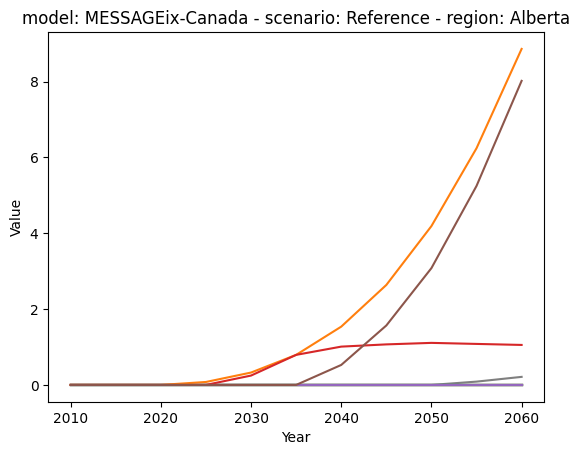

In [132]:
df_pyam.filter(variable = 'Secondary Energy|hydrogen*', region='Alberta').plot()

In [143]:
import math

import geopandas as gpd
import matplotlib.pyplot as plt
import pyam
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredOffsetbox, AuxTransformBox
from matplotlib.transforms import Affine2D
from matplotlib import cm


In [144]:


vars = [
    ('Industry', 'Coal', 'Final Energy|coal|coal_i|M1'),
    ('Industry', 'Gas', 'Final Energy|gas|Industry'),
    ('Industry', 'Oil', 'Final Energy|Oil|Industry'),
    ('Industry', 'Refined Liquid', 'Final Energy|Refined Liquid|Industry'),
    ('Industry', 'Electricity', 'Final Energy|Electricity|Industry'),
    ('Industry', 'Hydrogen', 'Final Energy|Hydrogen|Industry'),
    ('Industry', 'Final Energy By Sector', 'Final Energy|Industry'),
    ('Residents & Commercial', 'Coal', 'Final Energy|coal|coal_rc|M1'),
    ('Residents & Commercial', 'Gas', 'Final Energy|gas|RC'),
    ('Residents & Commercial', 'Oil', 'Final Energy|Oil|RC'),
    ('Residents & Commercial', 'Refined Liquid', 'Final Energy|Refined Liquid|RC'),
    ('Residents & Commercial', 'Electricity', 'Final Energy|Electricity|RC'),
    ('Residents & Commercial', 'Hydrogen', 'Final Energy|Hydrogen|RC'),
    ('Residents & Commercial', 'Final Energy By Sector', 'Final Energy|RC'),
    ('Transport', 'Coal', 'Final Energy|coal|coal_trp|M1'),
    ('Transport', 'Gas', 'Final Energy|gas|gas_trp|M1'),
    ('Transport', 'Oil', 'Final Energy|Oil|Transport'),
    ('Transport', 'Refined Liquid', 'Final Energy|Refined Liquid|Transport'),
    ('Transport', 'Electricity', 'Final Energy|Electricity|Transport'),
    ('Transport', 'Hydrogen', 'Final Energy|Hydrogen|Transport'),
    ('Transport', 'Final Energy By Sector', 'Final Energy|Transport'),
    ('Feedstocks (Non-Energy)', 'Coal', 'Final Energy|coal|coal_fs|M1'),
    ('Feedstocks (Non-Energy)', 'Gas', 'Final Energy|gas|gas_fs|M1'),
    ('Feedstocks (Non-Energy)', 'Oil', 'Final Energy|Oil|FS'),
    ('Feedstocks (Non-Energy)', 'Refined Liquid', 'Final Energy|Refined Liquid|FS'),
    ('Feedstocks (Non-Energy)', 'Final Energy By Sector', 'Final Energy|FS'),
    ('Final Energy By Fuel', 'Coal', 'Final Energy|coal|coal_fs|M1'),
    ('Final Energy By Fuel', 'Gas', 'Final Energy|gas|gas_fs|M1'),
    ('Final Energy By Fuel', 'Oil', 'Final Energy|Oil|FS'),
    ('Final Energy By Fuel', 'Refined Liquid', 'Final Energy|Refined Liquid|FS'),
    ('Final Energy By Fuel', 'Electricity', 'Final Energy|Electricity'),
    ('Final Energy By Fuel', 'Hydrogen', 'Final Energy|Hydrogen'),
    ('Final Energy By Fuel', 'Final Energy By Sector', 'Final Energy'),

]


def plot_grid(df_final, gdf, vars):
    df = df_final.timeseries().reset_index()

    # Align the region names by removing spaces in the CSV file region column
    df['region'] = df['region'].str.replace(' ', '')
    gdf['PRENAME'] = gdf['PRENAME'].str.replace(' ', '')

    # Calculate the number of rows and columns for the subplot grid
    n_vars = len(vars)
    n_cols = 5  # Number of columns in the grid
    n_rows = math.ceil(n_vars / n_cols)

    df.rename(columns={2050: 'value'}, inplace=True)

    # Merge the electricity generation data with the GeoDataFrame
    gdf_merged = gdf.merge(df[['region', 'value', 'variable']], left_on='PRENAME', right_on='region', how='left')

    # Create a colormap for value differences
    norm = plt.Normalize(vmin=gdf_merged['value'].min(), vmax=gdf_merged['value'].max())

    # Create a grid of plots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))

    for i, (index, column, variable) in enumerate(vars):
        print('Rendering:', index, column, variable, '...', i + 1, 'of', len(vars))
        # Filter the data for the specified variable
        gdf_plot = gdf_merged[gdf_merged['variable'] == variable]


        # Plot the map with province polygons colored by electricity generation values for the chosen year
        ax = axes[i // n_cols, i % n_cols]
        gdf_plot.plot(column='value', cmap='viridis', linewidth=0.8, ax=ax, edgecolor='black', legend=False, norm=norm)

        # # Add a colorbar for the scale
        # sm = plt.cm.ScalarMappable(norm=norm)
        # sm.set_array([])  # We don't need an actual array here
        # # We don't need an actual array here

        # save subplot to file
        # Remove axis for the subplot
        ax.set_axis_off()

        # save subplot to file
        plt.savefig(f'output_{index}_{column}.png')

    # Remove empty subplots
    for j in range(i + 1, n_rows * n_cols):
        fig.delaxes(axes[j // n_cols, j % n_cols])

    # Add a global colorbar for the entire figure
    cbar_ax = fig.add_axes([0.15, 0.05, 0.7, 0.02])  # Adjust the position and size as needed
    sm = plt.cm.ScalarMappable(norm=norm, cmap='viridis')
    fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', label='Value')
    for j in range(i + 1, n_rows * n_cols):
        fig.delaxes(axes[j // n_cols, j % n_cols])

    # save subplot to file

    # Show the plot
    plt.tight_layout()
    plt.show()
    # Save the plot to a file
    fig.savefig('output.png')

plot_grid(df_final, gdf, vars)


KeyError: 'value'

In [146]:
import yaml
import random

def read_yaml(file_path):
    with open(file_path, 'r') as file:
        data = yaml.safe_load(file)
    return data

def write_yaml(file_path, data):
    with open(file_path, 'w') as file:
        yaml.dump(data, file, default_flow_style=False)

def random_color():
    return "#{:06x}".format(random.randint(0, 0xFFFFFF))

def process_yaml(data):
    new_data = {}
    for category, items in data.items():
        group_color = random_color()
        for item in items:
            item_name = item
            new_data[item_name] = {
                "color": random_color(),
                "group": category,
                "group_color": group_color,
                "name": item_name
            }
    return new_data

def main():
    input_file = '/Users/muhammadawais/Documents/GitHub/message-ix-canada/model/output_mapping.yaml'  # Replace with your input YAML file path
    output_file = 'output_mapping_idea.yaml'  # Output file path
    data = read_yaml(input_file)
    processed_data = process_yaml(data)
    write_yaml(output_file, processed_data)

if __name__ == "__main__":
    main()

In [147]:
vars = [
    
]

SyntaxError: invalid syntax (4218935136.py, line 1)

In [160]:
df_pyam.filter(variable = 'Emission*').variable

['Emissions|BCA_Emission|BCA_AgWasteEM|P',
 'Emissions|BCA_Emission|BCA_IndNonEnergyEM|P',
 'Emissions|BCA_Emission|BCA_IntShipEM|P',
 'Emissions|BCA_Emission|BCA_WasteBurnEM|P',
 'Emissions|BCA_Emission|bio_hpl|M1',
 'Emissions|BCA_Emission|bio_istig_ccs|M1',
 'Emissions|BCA_Emission|bio_istig|M1',
 'Emissions|BCA_Emission|bio_ppl|M1',
 'Emissions|BCA_Emission|biomass_i|M1',
 'Emissions|BCA_Emission|biomass_rc|M1',
 'Emissions|BCA_Emission|coal_adv_ccs|M1',
 'Emissions|BCA_Emission|coal_adv|M1',
 'Emissions|BCA_Emission|coal_gas|M1',
 'Emissions|BCA_Emission|coal_hpl|M1',
 'Emissions|BCA_Emission|coal_i|M1',
 'Emissions|BCA_Emission|coal_ppl_u|M1',
 'Emissions|BCA_Emission|coal_ppl|M1',
 'Emissions|BCA_Emission|coal_rc|M1',
 'Emissions|BCA_Emission|eth_ic_trp|M1',
 'Emissions|BCA_Emission|eth_i|M1',
 'Emissions|BCA_Emission|eth_rc|M1',
 'Emissions|BCA_Emission|flaring_CO2|M1',
 'Emissions|BCA_Emission|foil_hpl|M1',
 'Emissions|BCA_Emission|foil_i|M1',
 'Emissions|BCA_Emission|foil_ppl